### **Analisis Data COVID-19 Terpadu**
Notebook ini telah dirapikan agar seluruh proses import, pembacaan data, dan analisis (Random Forest, Decision Tree, Logistic Regression, serta PCA & K-Means) berjalan secara runtut tanpa duplikasi proses unggah data.

In [2]:
# ==========================================
# 1. PENGGABUNGAN SEMUA LIBRARY (IMPORTS)
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Google Colab tools
from google.colab import files

# Scikit-Learn Preprocessing & Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Scikit-Learn Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Scikit-Learn Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    RocCurveDisplay,
    make_scorer
)

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


In [37]:
# ==========================================
# 2. UNGGAH DAN BACA DATASET (SATU KALI SAJA)
# ==========================================
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]

# Membaca dataset utama
df_master = pd.read_csv(nama_file)

print(f"File '{nama_file}' berhasil dibaca.")
print("Ukuran dataset asli:", df_master.shape)
display(df_master.head())

Saving covid 19 CountryWise.csv to covid 19 CountryWise (1).csv
File 'covid 19 CountryWise (1).csv' berhasil dibaca.
Ukuran dataset asli: (237, 12)


,Country,Region,Total Cases,Total Cases per 100k pop,New Cases (7 days),New Cases per 100k pop (7 days),New Cases (24 hours),Total Deaths,Total Deaths per 100k pop,New Deaths (7 days),New Deaths per 100k pop (7 days),New Deaths (24 hours)
0,United States of America,Americas,94152573,28444.658,416281,125.764,76462,1040506,314.350,2590,0.782,624
1,India,South-East Asia,44516479,3225.822,37843,2.742,6422,528250,38.279,160,0.012,34
2,Brazil,Americas,34544377,16251.633,53446,25.144,10420,685002,322.264,422,0.199,104
3,France,Europe,33766090,51916.394,150781,231.830,36147,151062,232.262,217,0.334,38
4,Germany,Europe,32604993,39204.380,203649,244.868,32168,148728,178.831,50,0.060,8


---
## **Yuniar Putri: Random Forest**

### **Penjelasan Langkah 1: Mempersiapkan dan Membersihkan Data**

Di sel kode berikut, kita mempersiapkan data mentah agar siap digunakan oleh model Random Forest:

* **`df_rf = df_master.copy()`**:
  * `df_master` adalah tabel data utama kita.
  * `.copy()` digunakan untuk membuat salinan data baru yang terpisah. Tujuannya agar perubahan yang kita lakukan pada `df_rf` tidak merusak atau mengubah data asli kita di `df_master`.
* **Tanda Kurung Siku Ganda `df_rf[...]`**:
  * Digunakan untuk memilih baris atau kolom tertentu dari tabel data.
* **`df_rf['Country'] != 'Other'`**:
  * Simbol `!=` berarti **"tidak sama dengan"**. Perintah ini menyaring data untuk membuang baris yang nama negaranya berisi kata `'Other'` (Lainnya), karena kita hanya ingin menganalisis negara yang spesifik.
* **`df_rf['Total Cases'] > 0`**:
  * Menyaring dan hanya mengambil negara yang memiliki jumlah kasus positif (`Total Cases`) lebih dari 0. Ini penting karena kita tidak bisa menghitung rasio fatalitas jika tidak ada kasus sama sekali.
* **`df_rf['CFR'] = (df_rf['Total Deaths'] / df_rf['Total Cases']) * 100`**:
  * Membuat kolom baru bernama **CFR** (*Case Fatality Rate* atau Tingkat Kematian Kasus).
  * Rumusnya adalah jumlah kematian (`Total Deaths`) dibagi jumlah kasus (`Total Cases`), lalu dikalikan 100 untuk mendapatkan nilai persentase (%).
* **`np.where(...)`**:
  * Ini adalah fungsi logika "jika-maka" dari library NumPy.
  * **`df_rf['CFR'] > median_cfr_rf`**: Jika nilai CFR suatu negara lebih besar dari nilai tengah (median),
  * **`'Tinggi'`**: Maka beri label atau kategori **'Tinggi'**.
  * **`'Rendah'`**: Jika tidak (lebih kecil atau sama dengan nilai tengah), maka beri label **'Rendah'**.
* **`.median()`**:
  * Berfungsi untuk mencari nilai tengah dari seluruh data CFR yang ada.
* **`.value_counts()`**:
  * Berfungsi untuk menghitung berapa banyak jumlah negara yang masuk ke dalam kategori 'Tinggi' dan berapa banyak yang masuk ke dalam kategori 'Rendah'.

In [4]:
# Membuat salinan data khusus untuk Random Forest
df_rf = df_master.copy()

# Pembersihan data awal
df_rf = df_rf[df_rf['Country'] != 'Other'].copy()
df_rf = df_rf[df_rf['Total Cases'] > 0].copy()

# Menghitung Case Fatality Rate (CFR)
df_rf['CFR'] = (df_rf['Total Deaths'] / df_rf['Total Cases']) * 100

# Pengkategorian CFR berdasarkan median
median_cfr_rf = df_rf['CFR'].median()
df_rf['Kategori_CFR'] = np.where(df_rf['CFR'] > median_cfr_rf, 'Tinggi', 'Rendah')

print("Median CFR (RF):", median_cfr_rf)
print(df_rf['Kategori_CFR'].value_counts())

Median CFR (RF): 0.8341785059041962
Kategori_CFR
Tinggi    116
Rendah    116
Name: count, dtype: int64


### **Penjelasan Langkah 2: Menentukan Fitur, Target, dan Membagi Data**

Di sel kode berikut, kita memisahkan data menjadi bahan pembelajaran (fitur) dan hal yang ingin ditebak (target), lalu membaginya untuk latihan dan ujian:

* **Fitur (`X_rf`) dan Target (`y_rf`)**:
  * **`X_rf` (Fitur)**: Adalah petunjuk atau karakteristik yang digunakan model untuk belajar. Di sini kita menggunakan kolom `New Cases per 100k pop (7 days)` (kasus baru per 100 ribu penduduk) dan `Region` (wilayah benua).
  * **`y_rf` (Target)**: Adalah label atau jawaban yang ingin ditebak oleh komputer, yaitu kolom `Kategori_CFR` ('Tinggi' atau 'Rendah').
* **`train_test_split(...)`**:
  * Fungsi dari Scikit-Learn untuk membagi satu dataset menjadi dua bagian secara acak:
    * **Data Training (80%)**: Digunakan untuk komputer belajar/berlatih mengenali pola.
    * **Data Testing (20%)**: Disimpan terlebih dahulu dan digunakan untuk menguji seberapa pintar komputer setelah belajar.
  * **`test_size=0.2`**: Menentukan bahwa 20% data akan digunakan sebagai data ujian (testing), dan sisanya 80% untuk latihan (training).
  * **`random_state=42`**: Angka pengunci acak agar pembagian data selalu sama setiap kali kode ini dijalankan.
  * **`stratify=y_rf`**: Memastikan bahwa proporsi kelas 'Tinggi' dan 'Rendah' di data latihan dan data ujian tetap seimbang (sama rata) sesuai data aslinya.

In [5]:
# Menentukan fitur dan target
X_rf = df_rf[['New Cases per 100k pop (7 days)', 'Region']]
y_rf = df_rf['Kategori_CFR']

# Splitting data (80:20)
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf
)

print("Jumlah training data (RF):", len(X_train_rf))
print("Jumlah testing data (RF):", len(X_test_rf))

Jumlah training data (RF): 185
Jumlah testing data (RF): 47


### **Penjelasan Langkah 3: Membuat Alur Kerja Otomatis (Pipeline) dan Melatih Model**

Di sel kode berikut, kita menyusun urutan persiapan data dan melatih model kecerdasan buatan:

* **`SimpleImputer(strategy='median' / 'most_frequent')`**:
  * Berfungsi untuk mendeteksi jika ada data yang kosong/hilang (NaN) dan otomatis mengisinya:
    * `median`: Mengisi data angka yang hilang dengan nilai tengah.
    * `most_frequent`: Mengisi data teks yang hilang dengan nilai yang paling sering muncul.
* **`OneHotEncoder(handle_unknown='ignore')`**:
  * Komputer tidak bisa membaca teks kategori langsung (seperti nama wilayah 'Europe', 'Africa'). Alat ini mengubah teks kategori tersebut menjadi angka biner `0` dan `1` agar bisa diproses model.
* **`ColumnTransformer(...)`**:
  * Penggabung proses. Alat ini memastikan proses pengisian data angka (`numeric_features`) dan pengubahan teks menjadi angka (`categorical_features`) berjalan secara bersamaan di kolomnya masing-masing.
* **`Pipeline(...)`**:
  * Berfungsi seperti ban berjalan di pabrik. Kita menyatukan tahap preprocessing (pembersihan data) dan tahap classifier (model algoritma komputer) menjadi satu kesatuan alur kerja agar rapi dan menghindari kesalahan kebocoran data.
* **`RandomForestClassifier(...)`**:
  * Ini adalah algoritma kecerdasan buatan kita. Random Forest bekerja dengan membuat ratusan "Pohon Keputusan" (Decision Tree) kecil dan menggabungkan hasil keputusan mereka untuk mendapatkan jawaban terbaik.
  * **`n_estimators=200`**: Membuat sebanyak 200 pohon keputusan.
  * **`class_weight='balanced'`**: Menyesuaikan bobot secara otomatis agar model adil jika jumlah data kategori 'Tinggi' dan 'Rendah' tidak persis sama.
* **`.fit(X_train_rf, y_train_rf)`**:
  * Ini adalah proses **"belajar"** atau pelatihan model. Komputer akan melihat data latihan (`X_train_rf`) beserta kunci jawabannya (`y_train_rf`) untuk menemukan pola hubungan di antaranya.

In [6]:
# Definisikan preprocessing
numeric_features = ['New Cases per 100k pop (7 days)']
numeric_transformer = Pipeline([('imputer', SimpleImputer(strategy='median'))])

categorical_features = ['Region']
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_rf = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Definisikan Pipeline Model Random Forest
rf_model = Pipeline([
    ('preprocessing', preprocessor_rf),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'))
])

# Latih model awal
rf_model.fit(X_train_rf, y_train_rf)
print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


### **Penjelasan Langkah 4: Memprediksi dan Melihat Hasil Evaluasi Model**

Setelah model selesai dilatih, sekarang saatnya menguji kepintarannya:

* **`.predict(X_test_rf)`**:
  * Proses **"menebak"** atau prediksi. Kita memberikan data ujian (`X_test_rf`) *tanpa kunci jawaban* kepada model, lalu model akan menebak apakah negara tersebut memiliki CFR 'Tinggi' atau 'Rendah' berdasarkan pola yang sudah dipelajarinya.
* **`classification_report(y_test_rf, y_pred_rf)`**:
  * Berfungsi menghasilkan laporan performa model berupa teks yang berisi:
    * **Precision (Presisi)**: Seberapa akurat tebakan model saat menebak kelas tertentu.
    * **Recall (Sensitivitas)**: Seberapa banyak model berhasil menemukan kembali data dari kelas tersebut.
    * **F1-Score**: Nilai rata-rata harmonis antara presisi dan recall.
    * **Accuracy (Akurasi)**: Persentase total tebakan model yang benar secara keseluruhan.

In [7]:
# Prediksi dan evaluasi awal
y_pred_rf = rf_model.predict(X_test_rf)
print(classification_report(y_test_rf, y_pred_rf))

              precision    recall  f1-score   support

      Rendah       0.69      0.92      0.79        24
      Tinggi       0.87      0.57      0.68        23

    accuracy                           0.74        47
   macro avg       0.78      0.74      0.73        47
weighted avg       0.78      0.74      0.74        47



### **Penjelasan Langkah 5: Membuat Grafik Confusion Matrix**

Di sini kita membuat tabel visual untuk melihat detail tebakan model:

* **`confusion_matrix(...)`**:
  * Membuat tabel pencocokan antara jawaban asli (`y_test_rf`) dengan jawaban tebakan komputer (`y_pred_rf`). Dari sini kita bisa melihat berapa banyak tebakan yang benar-benar tepat, dan kategori apa yang sering salah ditebak.
* **`ConfusionMatrixDisplay(...)`**:
  * Alat pembantu untuk menampilkan tabel angka di atas dalam bentuk visual berwarna.
* **`plt.title(...)` dan `plt.show()`**:
  * **`plt.title`**: Memberikan judul di bagian atas grafik.
  * **`plt.show()`**: Memerintahkan komputer untuk menampilkan grafik tersebut di layar laptop kita.

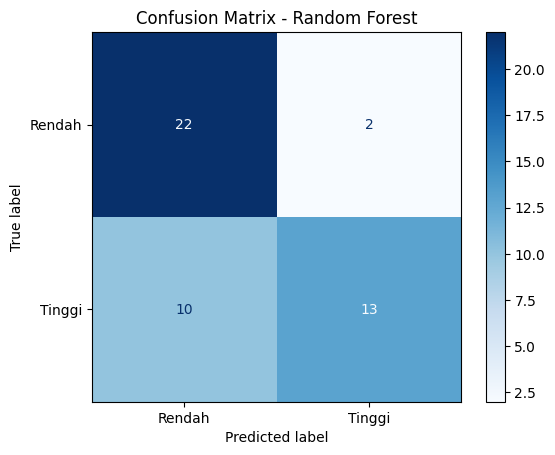

In [8]:
# Visualisasi Confusion Matrix
cm_rf = confusion_matrix(y_test_rf, y_pred_rf, labels=['Rendah', 'Tinggi'])
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Rendah', 'Tinggi'])
disp_rf.plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

### **Penjelasan Langkah 6: Membuat Kurva ROC dan Menghitung Nilai AUC**

Langkah ini bertujuan untuk melihat performa model dalam memisahkan dua kategori kelas:

* **`predict_proba(...)`**:
  * Bukan sekadar menebak langsung 'Tinggi'/'Rendah', melainkan mengeluarkan nilai probabilitas (persentase keyakinan model, misalnya: "model 85% yakin negara ini berkategori Tinggi").
* **`roc_curve(...)`**:
  * Menghitung nilai titik koordinat untuk membuat kurva ROC (*Receiver Operating Characteristic*). Kurva ini menunjukkan perbandingan antara tebakan benar yang positif dengan kesalahan tebakan.
* **`roc_auc_score(...)` atau AUC**:
  * Nilai area di bawah kurva ROC. Nilainya berkisar antara `0` sampai `1`:
    * Mendekati `1` berarti model sangat pintar dalam membedakan CFR 'Tinggi' dan 'Rendah'.
    * Nilai `0.5` berarti model hanya menebak secara acak (seperti melempar koin).
* **`plt.figure(figsize=(7, 5))`**:
  * Mengatur ukuran bidang gambar grafik (lebar 7 inci, tinggi 5 inci).
* **`plt.plot(...)`**:
  * Menggambar garis grafik kurva berdasarkan data yang dihitung.
* **`plt.legend()`**:
  * Menampilkan kotak keterangan atau legenda di dalam grafik agar pembaca tahu arti dari garis warna tersebut.

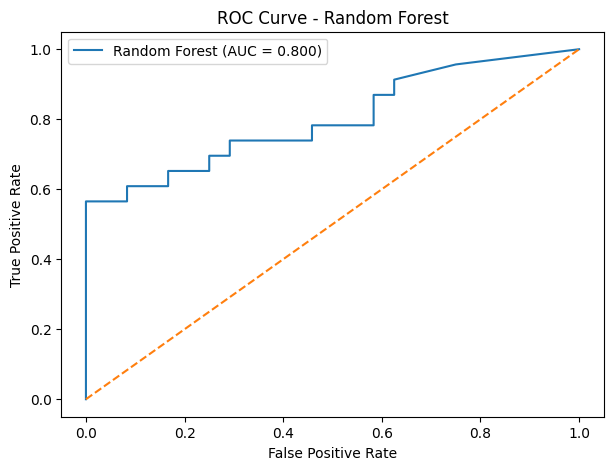

ROC-AUC: 0.7998188405797102


In [9]:
# Visualisasi ROC-AUC
positive_class_rf = list(rf_model.classes_).index('Tinggi')
y_prob_rf = rf_model.predict_proba(X_test_rf)[:, positive_class_rf]
y_binary_rf = (y_test_rf == 'Tinggi').astype(int)

fpr_rf, tpr_rf, _ = roc_curve(y_binary_rf, y_prob_rf)
auc_rf = roc_auc_score(y_binary_rf, y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()
print("ROC-AUC:", auc_rf)

### **Penjelasan Langkah 7: Mencari Pengaturan Model Terbaik (Hyperparameter Tuning)**

Di sel kode berikut, kita melakukan eksperimen otomatis untuk mencari kombinasi pengaturan model yang paling optimal:

* **`param_grid_rf`**:
  * Daftar "tombol setelan" model yang ingin kita uji coba. Misalnya mencoba jumlah pohon (`n_estimators`) sebanyak 100, 200, atau 300, serta kedalaman pohon (`max_depth`).
* **`StratifiedKFold(n_splits=5, ...)`**:
  * Teknik **K-Fold Cross Validation**. Data latihan dibagi menjadi 5 bagian kecil. Model akan dilatih 5 kali secara bergantian, di mana setiap kali latihan, 4 bagian digunakan untuk belajar dan 1 bagian digunakan untuk ujian kecil. Ini berguna agar hasil evaluasi model stabil dan tidak bias.
* **`GridSearchCV(...)`**:
  * Mesin pencari otomatis. Alat ini akan mencoba *setiap kombinasi* pengaturan yang kita tulis di `param_grid_rf` satu per satu menggunakan metode Cross Validation, lalu mencatat setelan mana yang menghasilkan skor F1-macro (`scoring='f1_macro'`) paling tinggi.
  * **`n_jobs=-1`**: Memerintahkan komputer untuk menggunakan seluruh tenaga prosesornya agar proses pencarian berjalan lebih cepat.

In [10]:
# Tuning Hyperparameter menggunakan GridSearchCV
param_grid_rf = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 5, 10, 15],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

cv_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_rf = GridSearchCV(estimator=rf_model, param_grid=param_grid_rf, cv=cv_rf, scoring='f1_macro', n_jobs=-1)
grid_search_rf.fit(X_train_rf, y_train_rf)

print("Parameter terbaik:", grid_search_rf.best_params_)
print("Skor F1-macro terbaik:", grid_search_rf.best_score_)

Parameter terbaik: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
Skor F1-macro terbaik: 0.7449535864241746


### **Penjelasan Langkah 8: Menguji Model Terbaik Hasil Tuning**

Setelah mendapatkan setelan terbaik dari proses pencarian otomatis sebelumnya, kita langsung menggunakannya pada data ujian:

* **`grid_search_rf.best_estimator_`**:
  * Mengambil model Random Forest yang sudah dikonfigurasi dengan setelan terbaik/paling pintar yang ditemukan dari proses GridSearchCV.
* **`classification_report(...)`**:
  * Menampilkan laporan performa akhir model terbaik untuk kita bandingkan apakah hasil akurasinya meningkat setelah disetel ulang.

In [11]:
# Evaluasi Model Terbaik setelah Tuning
best_rf = grid_search_rf.best_estimator_
y_pred_tuned_rf = best_rf.predict(X_test_rf)
print(classification_report(y_test_rf, y_pred_tuned_rf))

              precision    recall  f1-score   support

      Rendah       0.69      0.83      0.75        24
      Tinggi       0.78      0.61      0.68        23

    accuracy                           0.72        47
   macro avg       0.73      0.72      0.72        47
weighted avg       0.73      0.72      0.72        47



### **Penjelasan Langkah 9: Evaluasi Validasi Silang (Cross Validation) Awal**

Langkah ini digunakan untuk menguji keandalan model awal kita secara menyeluruh menggunakan teknik validasi silang:

* **`cross_validate(...)`**:
  * Mirip dengan GridSearchCV, fungsi ini menguji model awal berkali-kali (5 lipatan/splits) untuk mendapatkan gambaran performa model yang lebih jujur dan objektif pada seluruh bagian data latihan.
* **`cv_results_rf[metric].mean()` & `.std()`**:
  * **`mean()`**: Nilai rata-rata performa model dari 5 kali pengujian.
  * **`std()`**: Standar deviasi (selisih variasi). Menunjukkan seberapa stabil performa model tersebut. Semakin kecil nilainya, semakin stabil modelnya.

In [12]:
# Cross Validation awal
cv_results_rf = cross_validate(
    rf_model, X_train_rf, y_train_rf, cv=cv_rf,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
)

for metric in ['test_accuracy', 'test_precision_macro', 'test_recall_macro', 'test_f1_macro']:
    print(f"{metric} : {cv_results_rf[metric].mean():.3f} +/- {cv_results_rf[metric].std():.3f}")

test_accuracy : 0.697 +/- 0.067
test_precision_macro : 0.699 +/- 0.066
test_recall_macro : 0.698 +/- 0.067
test_f1_macro : 0.697 +/- 0.068


### **Penjelasan Langkah 10: Melihat Fitur yang Paling Berpengaruh (Feature Importance)**

Di langkah terakhir bagian Random Forest ini, kita mencari tahu faktor apa yang paling menentukan tebakan model komputer:

* **`best_rf.named_steps['preprocessing'].get_feature_names_out()`**:
  * Mengambil semua nama kolom atau fitur setelah melalui proses perubahan format data sebelumnya.
* **`best_rf.named_steps['classifier'].feature_importances_`**:
  * Nilai tingkat pentingnya suatu fitur. Fitur dengan nilai tertinggi adalah variabel yang paling sering digunakan dan paling membantu pohon-pohon keputusan dalam menentukan kategori CFR suatu negara.
* **`pd.DataFrame(...)`**:
  * Membuat tabel baru untuk merangkum nama fitur beserta nilai pentingnya.
* **`.sort_values(by='Importance', ascending=False)`**:
  * Mengurutkan tabel berdasarkan nilai penting dari yang paling besar ke yang paling kecil.
* **`sns.barplot(...)`**:
  * Menggunakan library Seaborn (`sns`) untuk membuat grafik batang mendatar agar kita bisa melihat dengan jelas variabel mana yang paling berpengaruh secara visual.

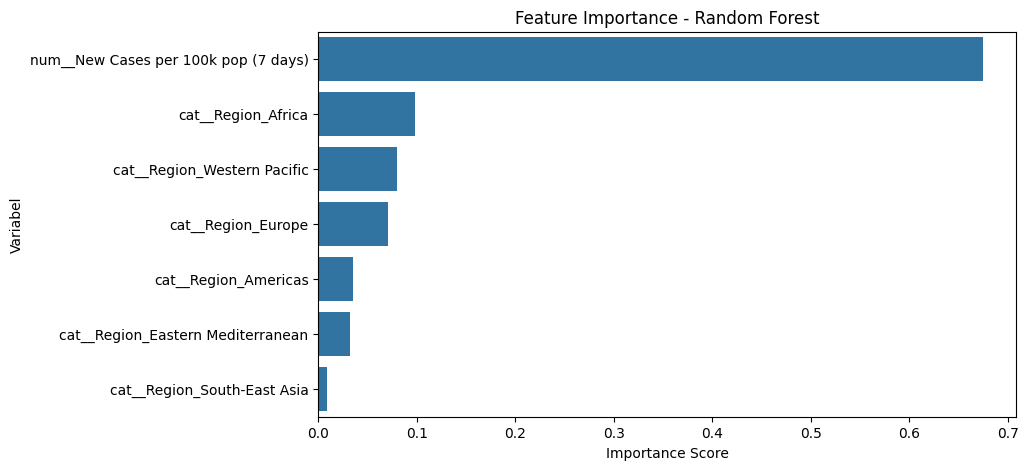

In [13]:
# Feature Importance
feature_names_rf = best_rf.named_steps['preprocessing'].get_feature_names_out()
importances_rf = best_rf.named_steps['classifier'].feature_importances_

importance_df_rf = pd.DataFrame({
    'Fitur': feature_names_rf,
    'Importance': importances_rf
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df_rf, x='Importance', y='Fitur')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Variabel')
plt.show()

---
## **Duara Karami: Decision Tree**

### **Penjelasan Langkah 1: Mempersiapkan dan Membersihkan Data untuk Pohon Keputusan**

Di sel kode berikut, kita mempersiapkan data agar siap dianalisis menggunakan model Decision Tree (Pohon Keputusan):

* **`df_dt = df_master.copy()`**:
  * Menyalin tabel data utama (`df_master`) menjadi tabel baru bernama `df_dt` agar data asli tidak terganggu.
* **`df_dt["CFR"] = (df_dt["Total Deaths"] / df_dt["Total Cases"])*100`**:
  * Menghitung nilai CFR (Tingkat Kematian Kasus) dalam bentuk persen (%).
* **`df_dt.replace([np.inf, -np.inf], np.nan)`**:
  * Jika ada pembagian dengan angka 0, Python akan menghasilkan nilai tak terhingga (`inf`). Perintah ini mengubah nilai tak terhingga tersebut menjadi nilai kosong biasa (`NaN`) agar tidak merusak perhitungan.
* **`.dropna(subset=["CFR"])`**:
  * Menghapus baris negara yang tidak memiliki nilai CFR (kosong) dari tabel data.
* **`df_dt["Risk_Level"] = np.where(df_dt["CFR"] > median_cfr_dt, 1, 0)`**:
  * Mengelompokkan negara menjadi dua tingkat risiko:
    * Angka **`1`**: Untuk negara yang nilai CFR-nya berada di atas nilai tengah (median) atau bisa disebut **Risiko Tinggi**.
    * Angka **`0`**: Untuk negara yang nilai CFR-nya di bawah atau sama dengan nilai tengah, alias **Risiko Rendah**.
* **`.map({0: "Risiko Rendah", 1: "Risiko Tinggi"})`**:
  * Mengubah label angka `0` dan `1` sebelumnya menjadi teks yang mudah dibaca, yaitu 'Risiko Rendah' dan 'Risiko Tinggi'.

In [14]:
# Membuat salinan data khusus untuk Decision Tree
df_dt = df_master.copy()

# Menghitung CFR
df_dt["CFR"] = (df_dt["Total Deaths"] / df_dt["Total Cases"]) * 100
df_dt = df_dt.replace([np.inf, -np.inf], np.nan).dropna(subset=["CFR"]).copy()

# Menentukan median CFR
median_cfr_dt = df_dt["CFR"].median()

# Pembagian kategori risiko
df_dt["Risk_Level"] = np.where(df_dt["CFR"] > median_cfr_dt, 1, 0)
df_dt["Risk_Category"] = df_dt["Risk_Level"].map({0: "Risiko Rendah", 1: "Risiko Tinggi"})

print("Jumlah data valid (DT):", len(df_dt))
print("Median CFR (DT):", round(median_cfr_dt, 4), "%")

Jumlah data valid (DT): 233
Median CFR (DT): 0.847 %


### **Penjelasan Langkah 2: Membuat Grafik Distribusi Kategori Risiko**

Di sel kode ini, kita akan melihat perbandingan jumlah negara untuk masing-masing kategori risiko:

* **`sns.countplot(data=df_dt, x="Risk_Category")`**:
  * Menggunakan library Seaborn (`sns`) untuk membuat grafik batang yang secara otomatis menghitung dan menampilkan berapa jumlah negara yang masuk kelompok 'Risiko Rendah' dan 'Risiko Tinggi'.
* **`plt.xlabel(...)` dan `plt.ylabel(...)`**:
  * `plt.xlabel`: Menentukan teks label untuk sumbu mendatar (Kategori Risiko).
  * `plt.ylabel`: Menentukan teks label untuk sumbu tegak (Jumlah Negara).

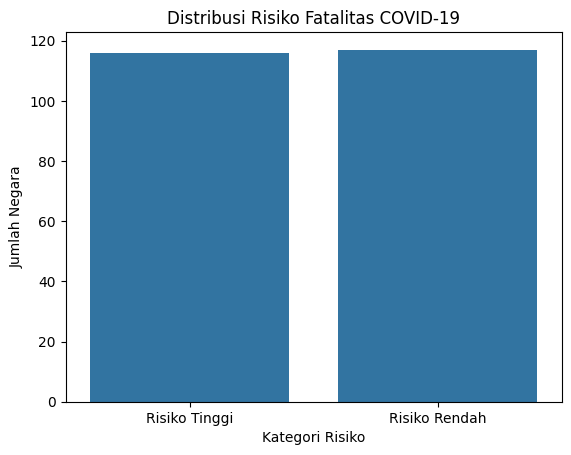

In [15]:
# Visualisasi Distribusi Kategori Risiko
sns.countplot(data=df_dt, x="Risk_Category")
plt.title("Distribusi Risiko Fatalitas COVID-19")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Negara")
plt.show()

### **Penjelasan Langkah 3: Menentukan Indikator (Fitur) dan Membagi Data**

Di sel kode berikut, kita memisahkan data untuk proses belajar mengajar komputer:

* **`X_dt = df_dt[fitur_numerik_dt + fitur_kategorik_dt]`**:
  * Menentukan variabel indikator (`X_dt`) yang akan digunakan untuk memprediksi, yaitu jumlah total kasus, kasus baru dalam 7 hari terakhir, dan wilayah benua (`Region`).
* **`y_dt = df_dt["Risk_Level"]`**:
  * Menentukan target yang ingin ditebak (`y_dt`), yaitu tingkat risiko (0 atau 1).
* **`train_test_split(...)`**:
  * Membagi data secara acak menjadi data latihan (80%) dan data ujian (20%).
  * **`stratify=y_dt`**: Memastikan persentase kelas risiko tinggi dan rendah tetap seimbang baik di data latihan maupun data ujian.

In [16]:
# Menentukan fitur dan target
fitur_numerik_dt = ["Total Cases per 100k pop", "New Cases per 100k pop (7 days)"]
fitur_kategorik_dt = ["Region"]

X_dt = df_dt[fitur_numerik_dt + fitur_kategorik_dt]
y_dt = df_dt["Risk_Level"]

# Splitting Dataset (80:20)
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(
    X_dt, y_dt, test_size=0.2, stratify=y_dt, random_state=42
)

print("Jumlah data training (DT):", len(X_train_dt))
print("Jumlah data testing (DT):", len(X_test_dt))

Jumlah data training (DT): 186
Jumlah data testing (DT): 47


### **Penjelasan Langkah 4: Membuat Alur Preprocessing dan Model Pohon Keputusan**

Di sel kode berikut, kita menyusun langkah otomatis untuk merapikan data sebelum dimasukkan ke dalam model:

* **`Pipeline(...)`**:
  * Berfungsi sebagai pengikat langkah. Misalnya, mengisi data yang kosong terlebih dahulu (`SimpleImputer`), kemudian mengubah teks kategori menjadi angka (`OneHotEncoder`), lalu meneruskannya ke model utama.
* **`DecisionTreeClassifier(criterion="gini", random_state=42)`**:
  * Ini adalah algoritma **Pohon Keputusan** kita.
  * **`criterion="gini"`**: Metode matematika untuk mengukur seberapa bersih atau murni pembagian cabang pada pohon keputusan.
* **`.fit(X_train_dt, y_train_dt)`**:
  * Memulai proses pembelajaran bagi komputer menggunakan data latihan.

In [17]:
# Pipeline preprocessing
prep_numerik_dt = Pipeline([("imputer", SimpleImputer(strategy="median"))])
prep_kategorik_dt = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_dt = ColumnTransformer([
    ("numerik", prep_numerik_dt, fitur_numerik_dt),
    ("kategorik", prep_kategorik_dt, fitur_kategorik_dt)
])

# Inisialisasi Model Decision Tree
model_dt = Pipeline([
    ("preprocessor", preprocessor_dt),
    ("classifier", DecisionTreeClassifier(criterion="gini", random_state=42))
])

# Latih Model
model_dt.fit(X_train_dt, y_train_dt)
print("Model Decision Tree berhasil dilatih.")

Model Decision Tree berhasil dilatih.


### **Penjelasan Langkah 5: Menguji Kestabilan Model dengan Validasi Silang (Cross-Validation)**

Langkah ini bertujuan untuk memastikan model kita tidak hanya pintar karena kebetulan saja:

* **`StratifiedKFold(n_splits=5, ...)`**:
  * Membagi data latihan menjadi 5 kelompok kecil. Proses latihan dan ujian akan diulang sebanyak 5 kali agar hasil evaluasi lebih akurat.
* **`cross_validate(...)`**:
  * Melakukan simulasi ujian 5 kali tersebut secara otomatis dan menyimpan skor keberhasilan model.
* **`pd.DataFrame(...)`**:
  * Menyajikan hasil rata-rata (*Mean*) skor akurasi, presisi, recall, dan F1-Score dari simulasi ujian ke dalam bentuk tabel yang rapi.

In [18]:
# Cross-Validation Decision Tree
cv_dt = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_dt = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, average="macro", zero_division=0),
    "recall": make_scorer(recall_score, average="macro", zero_division=0),
    "f1": make_scorer(f1_score, average="macro", zero_division=0)
}

cv_results_dt = cross_validate(model_dt, X_train_dt, y_train_dt, cv=cv_dt, scoring=scoring_dt)

hasil_cv_dt = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Mean": [
        cv_results_dt["test_accuracy"].mean(),
        cv_results_dt["test_precision"].mean(),
        cv_results_dt["test_recall"].mean(),
        cv_results_dt["test_f1"].mean()
    ],
    "Std": [
        cv_results_dt["test_accuracy"].std(),
        cv_results_dt["test_precision"].std(),
        cv_results_dt["test_recall"].std(),
        cv_results_dt["test_f1"].std()
    ]
})
display(hasil_cv_dt.round(4))

,Metrik,Mean,Std
0,Accuracy,0.7640,0.0592
1,Precision,0.7684,0.0614
2,Recall,0.7637,0.0590
3,F1-Score,0.7630,0.0589


### **Penjelasan Langkah 6: Mencari Setelan Pohon Keputusan Terbaik (GridSearchCV)**

Kita mencari kombinasi setelan model (seperti kedalaman maksimal pohon) yang paling pas:

* **`param_grid_dt`**:
  * Daftar pilihan setelan yang akan kita uji, misalnya kedalaman pohon (`max_depth`) dari tingkat 2 hingga tingkat 6.
* **`GridSearchCV(...)`**:
  * Menguji seluruh kombinasi setelan tersebut satu per satu secara otomatis untuk menemukan setelan yang paling pintar.
* **`.best_params_`**:
  * Menampilkan kombinasi setelan terbaik yang berhasil ditemukan.

In [19]:
# Hyperparameter Tuning GridSearchCV
param_grid_dt = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [2, 3, 4, 5, 6, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

grid_search_dt = GridSearchCV(estimator=model_dt, param_grid=param_grid_dt, cv=cv_dt, scoring="f1_macro", n_jobs=-1)
grid_search_dt.fit(X_train_dt, y_train_dt)

print("Parameter terbaik (DT):", grid_search_dt.best_params_)
print("Nilai F1-score terbaik:", round(grid_search_dt.best_score_, 4))

Parameter terbaik (DT): {'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Nilai F1-score terbaik: 0.8267


### **Penjelasan Langkah 7: Menguji Model Terbaik pada Data Ujian**

Kita menguji performa akhir model terbaik menggunakan data yang belum pernah dipelajari sebelumnya:

* **`best_dt = grid_search_dt.best_estimator_`**:
  * Mengambil model yang sudah menggunakan setelan terbaik hasil pencarian otomatis sebelumnya.
* **`accuracy_score`, `precision_score`, `recall_score`, `f1_score`**:
  * Menghitung nilai statistik performa model.
* **`classification_report(...)`**:
  * Menampilkan rangkuman detail seberapa baik model menebak kelompok 'Risiko Rendah' dan 'Risiko Tinggi'.

In [20]:
# Evaluasi Model Terbaik setelah Tuning
best_dt = grid_search_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test_dt)

hasil_evaluasi_dt = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Nilai": [
        accuracy_score(y_test_dt, y_pred_dt),
        precision_score(y_test_dt, y_pred_dt, average="macro", zero_division=0),
        recall_score(y_test_dt, y_pred_dt, average="macro", zero_division=0),
        f1_score(y_test_dt, y_pred_dt, average="macro", zero_division=0)
    ]
})
display(hasil_evaluasi_dt.round(4))
print("\nClassification Report (DT):")
print(classification_report(y_test_dt, y_pred_dt, labels=[0, 1], target_names=["Risiko Rendah", "Risiko Tinggi"], zero_division=0))

,Metrik,Nilai
0,Accuracy,0.8085
1,Precision,0.8139
2,Recall,0.8071
3,F1-Score,0.8071



Classification Report (DT):
               precision    recall  f1-score   support

Risiko Rendah       0.78      0.88      0.82        24
Risiko Tinggi       0.85      0.74      0.79        23

     accuracy                           0.81        47
    macro avg       0.81      0.81      0.81        47
 weighted avg       0.81      0.81      0.81        47



### **Penjelasan Langkah 8: Membuat Grafik Confusion Matrix**

Langkah ini memvisualisasikan ketepatan tebakan model:

* **`confusion_matrix(...)`**:
  * Menghitung jumlah tebakan yang benar (di garis diagonal tabel) dan tebakan yang salah.
* **`disp_dt.plot(cmap="Blues")`**:
  * Menampilkan tabel tersebut dalam warna biru visual yang mudah dibaca.

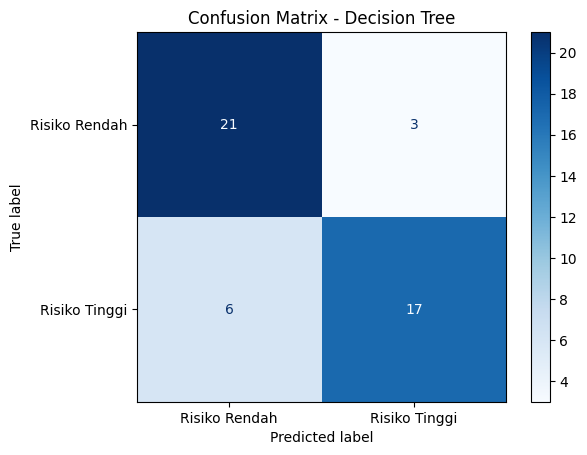

In [21]:
# Visualisasi Confusion Matrix - Decision Tree
cm_dt = confusion_matrix(y_test_dt, y_pred_dt, labels=[0, 1])
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=["Risiko Rendah", "Risiko Tinggi"])
disp_dt.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

### **Penjelasan Langkah 9: Membuat Kurva ROC**

Kurva ini membantu kita menilai kualitas klasifikasi model:

* **`RocCurveDisplay.from_estimator(...)`**:
  * Menggambar kurva ROC secara otomatis. Semakin kurva ini melengkung mendekati sudut kiri atas, berarti kemampuan model dalam membedakan risiko tinggi dan rendah semakin bagus.

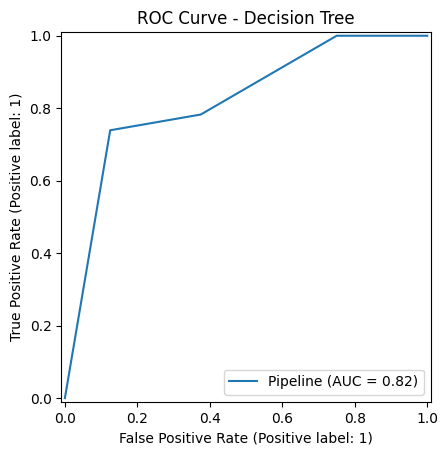

In [22]:
# ROC-AUC Curve - Decision Tree
RocCurveDisplay.from_estimator(best_dt, X_test_dt, y_test_dt)
plt.title("ROC Curve - Decision Tree")
plt.show()

### **Penjelasan Langkah 10: Menggambar Struktur Pohon Keputusan**

Di sini kita akan melihat visualisasi bagaimana komputer mengambil keputusan seperti diagram alur bergambar:

* **`plot_tree(...)`**:
  * Menggambar struktur pohon keputusan yang berisi cabang-cabang pertanyaan (jika indikator A > nilai X, maka pergi ke cabang kanan, jika tidak ke cabang kiri).
  * **`filled=True`**: Memberi warna pada kotak keputusan untuk membedakan kategori dominan.
  * **`max_depth=3`**: Membatasi gambar pohon hanya sampai tingkat ke-3 agar diagram tidak terlalu rumit dan tetap mudah dibaca.

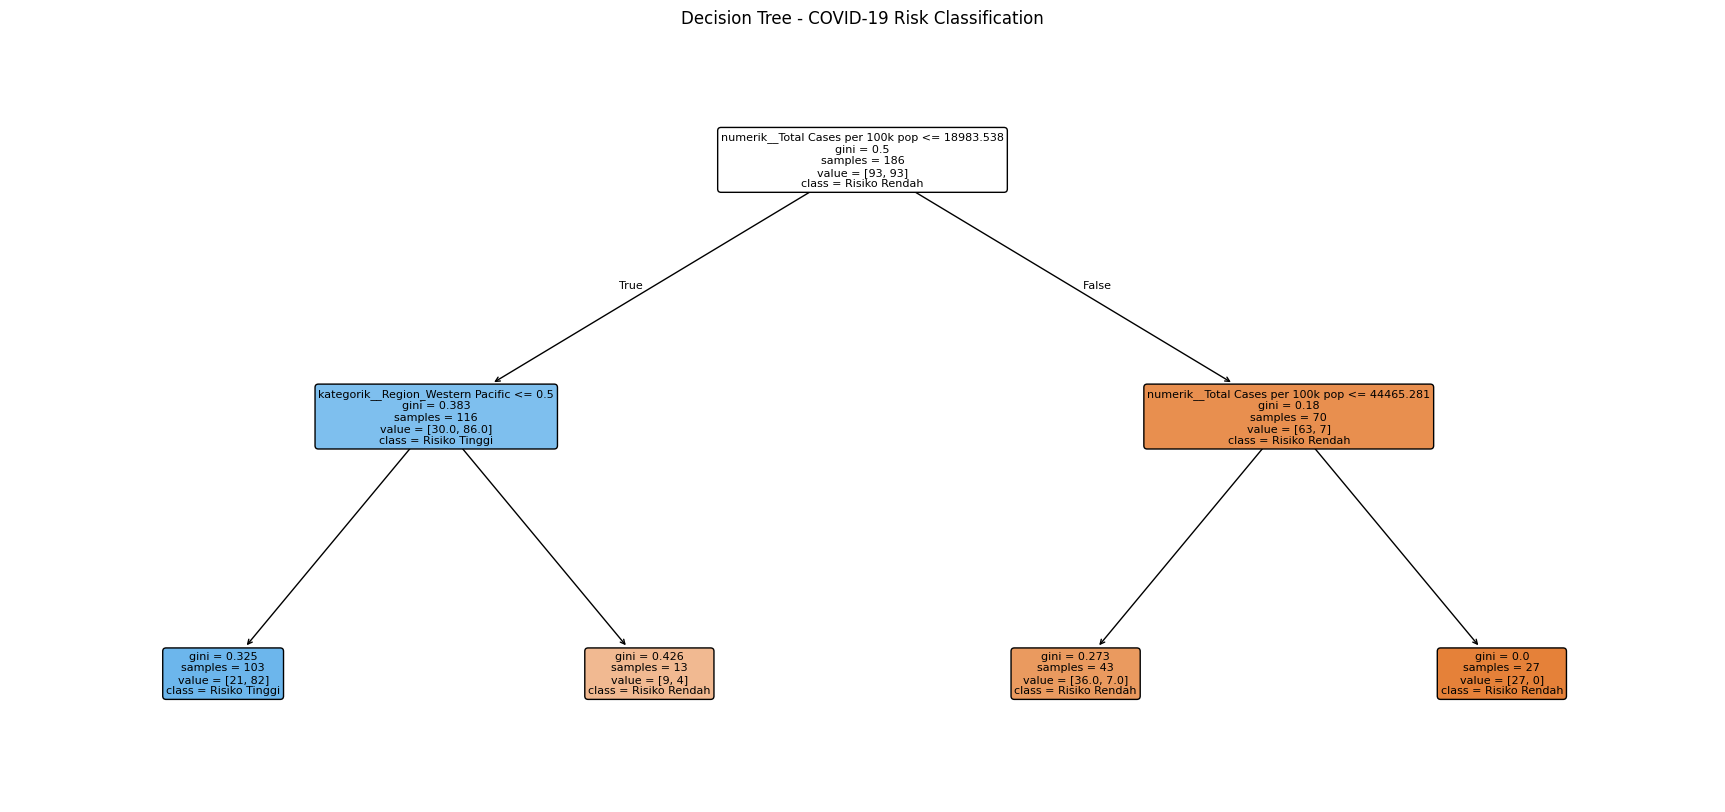

In [23]:
# Visualisasi Tree
tree_model = best_dt.named_steps["classifier"]
feature_names_dt = best_dt.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model, feature_names=feature_names_dt,
    class_names=["Risiko Rendah", "Risiko Tinggi"],
    filled=True, rounded=True, max_depth=3, fontsize=8
)
plt.title("Decision Tree - COVID-19 Risk Classification")
plt.show()

### **Penjelasan Langkah 11: Melihat Fitur Paling Berpengaruh**

Langkah terakhir untuk mengetahui faktor penentu keputusan:

* **`tree_model.feature_importances_`**:
  * Mengeluarkan nilai seberapa besar pengaruh masing-masing variabel data terhadap pembentukan keputusan.
* **`sns.barplot(...)`**:
  * Menggambar grafik batang untuk mengurutkan indikator dari yang paling berpengaruh hingga yang paling kecil pengaruhnya.

,Feature,Importance
0,numerik__Total Cases per 100k pop,0.8698
8,kategorik__Region_Western Pacific,0.1302
1,numerik__New Cases per 100k pop (7 days),0.0000
3,kategorik__Region_Americas,0.0000
2,kategorik__Region_Africa,0.0000
4,kategorik__Region_Eastern Mediterranean,0.0000
5,kategorik__Region_Europe,0.0000
6,kategorik__Region_Other,0.0000
7,kategorik__Region_South-East Asia,0.0000


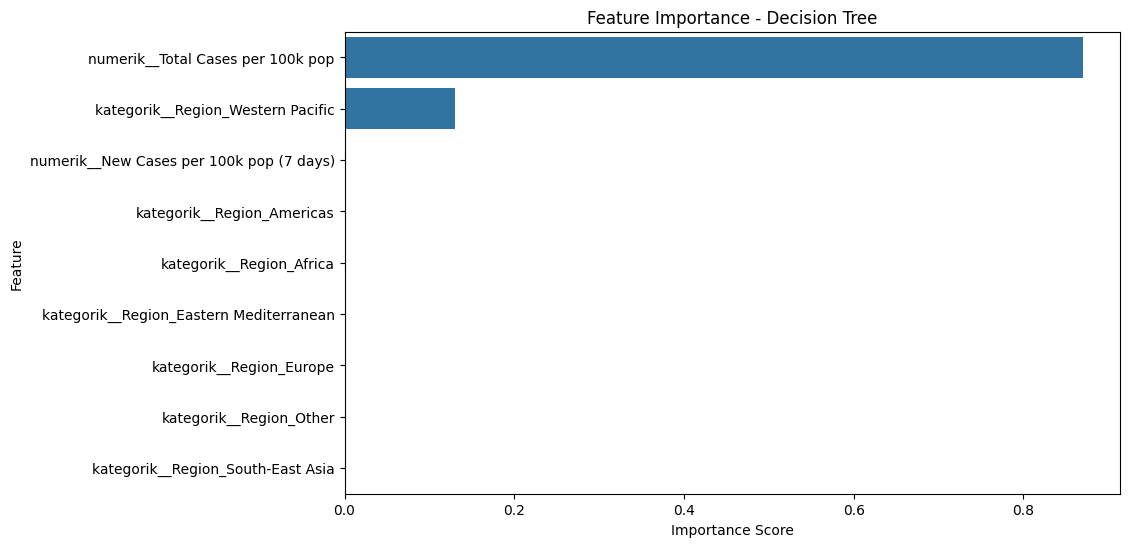

In [24]:
# Feature Importance - Decision Tree
importance_dt = tree_model.feature_importances_
importance_df_dt = pd.DataFrame({"Feature": feature_names_dt, "Importance": importance_dt})
importance_df_dt = importance_df_dt.sort_values(by="Importance", ascending=False)

display(importance_df_dt.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df_dt, x="Importance", y="Feature")
plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

---
## **Alfi Fauziah: Logistic Regression**

### **Penjelasan Langkah 1: Mempersiapkan Data, Standardisasi, dan Membuat Model**

Di sel kode berikut, kita mempersiapkan data dan mengatur alur pemrosesan data khusus untuk model Logistic Regression:

* **`X_lr` (Fitur) dan `y_lr` (Target)**:
  * Kita memilih variabel penentu (`X_lr`) berupa total kasus, kasus baru dalam 7 hari terakhir, dan wilayah benua.
  * Targetnya (`y_lr`) adalah kategori tingkat kematian kasus (`Kategori_CFR`), yaitu 'Tinggi' atau 'Rendah'.
* **`StandardScaler()`**:
  * Berfungsi sebagai penyetara skala (standardisasi). Karena nilai total kasus bisa bernilai puluhan juta sedangkan kasus baru hanya ribuan, ketimpangan angka ini dapat membingungkan model. Alat ini menyamakan skala semua data angka agar rata-ratanya bernilai 0 dan variansinya 1.
* **`LogisticRegression(max_iter=1000, random_state=42)`**:
  * Ini adalah algoritma **Regresi Logistik** kita. Berbeda dengan regresi biasa, regresi logistik digunakan untuk mengklasifikasikan data ke dalam kelompok (seperti mendeteksi 'Tinggi' atau 'Rendah') dengan cara menghitung peluang terjadinya suatu kelas biner.
  * **`max_iter=1000`**: Memperbolehkan komputer mengulang perhitungan hingga maksimal 1000 kali agar mencapai hasil kalkulasi yang paling tepat.
* **`.fit(X_train_lr, y_train_lr)`**:
  * Melatih model agar mempelajari hubungan antara variabel indikator dengan status kategori CFR.

In [25]:
# Membuat salinan data khusus untuk Logistic Regression
df_lr = df_master.copy()

# Menggunakan variabel target dari analisis terpisah untuk mencegah cross-contamination
# (Sesuai dengan target di model Alfi, menggunakan data split training sebelumnya)
# Kita set up ulang X dan y yang sesuai untuk Logistic Regression

# Model Alfi menggunakan 'Total Cases per 100k pop' dan 'New Cases per 100k pop (7 days)'
# Serta 'Kategori_CFR' sebagai label target biner (menggunakan dataset rf)

X_lr = df_rf[['Total Cases per 100k pop', 'New Cases per 100k pop (7 days)', 'Region']]
y_lr = df_rf['Kategori_CFR']

# Split ulang data
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42, stratify=y_lr
)

# Preprocessing untuk Logistic Regression
numeric_features_lr = ['Total Cases per 100k pop', 'New Cases per 100k pop (7 days)']
categorical_features_lr = ['Region']

numeric_transformer_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_lr = ColumnTransformer([
    ('num', numeric_transformer_lr, numeric_features_lr),
    ('cat', categorical_transformer_lr, categorical_features_lr)
])

# Inisialisasi Model Logistic Regression
lr_model = Pipeline([
    ('preprocessing', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Training Model
lr_model.fit(X_train_lr, y_train_lr)
print("Model Logistic Regression berhasil dilatih!")

Model Logistic Regression berhasil dilatih!


### **Penjelasan Langkah 2: Memprediksi dan Mengevaluasi Model Awal**

Kita menguji performa awal model Logistic Regression menggunakan data ujian:

* **`accuracy_score(...)`**:
  * Menghitung persentase total prediksi model yang benar dibanding seluruh data yang diuji.
* **`classification_report(...)`**:
  * Rangkuman performa yang memperlihatkan presisi, sensitivitas (recall), dan nilai keseimbangan F1-Score dari tebakan kelas 'Tinggi' dan 'Rendah'.
* **`confusion_matrix(...)`**:
  * Tabel pencocokan tebakan komputer dengan kenyataan (jawaban yang benar).

In [26]:
# Prediksi awal dan evaluasi
y_pred_lr = lr_model.predict(X_test_lr)
print("Akurasi Logistic Regression:", accuracy_score(y_test_lr, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test_lr, y_pred_lr))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, y_pred_lr))

Akurasi Logistic Regression: 0.8936170212765957

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.88      0.92      0.90        24
      Tinggi       0.91      0.87      0.89        23

    accuracy                           0.89        47
   macro avg       0.89      0.89      0.89        47
weighted avg       0.89      0.89      0.89        47


Confusion Matrix:
[[22  2]
 [ 3 20]]


### **Penjelasan Langkah 3: Menguji Kestabilan dengan Validasi Silang (Cross-Validation)**

Kita melakukan pengujian kestabilan model agar performa yang dihasilkan terbukti konsisten di berbagai bagian data:

* **`cross_validate(..., cv=cv_lr, scoring=['accuracy', 'f1_macro'])`**:
  * Menjalankan pengujian berulang (5 kali lipatan) dan mencatat skor akurasi serta F1-Score pada setiap putaran secara otomatis.
* **`.mean()`**:
  * Mengambil nilai rata-rata dari seluruh pengujian tersebut untuk melihat kemampuan model yang sebenarnya.

In [27]:
# Cross Validation - Logistic Regression
cv_lr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_cv_lr = cross_validate(lr_model, X_train_lr, y_train_lr, cv=cv_lr, scoring=['accuracy', 'f1_macro'])

print("Akurasi rata-rata:", hasil_cv_lr['test_accuracy'].mean())
print("Rata-rata F1-score:", hasil_cv_lr['test_f1_macro'].mean())

Akurasi rata-rata: 0.7891891891891893
Rata-rata F1-score: 0.7871182673621698


### **Penjelasan Langkah 4: Mencari Setelan Terbaik (GridSearchCV)**

Kita mencari kombinasi kekuatan setelan model yang paling optimal:

* **`param_grid_lr`**:
  * **`'classifier__C'`**: Merupakan parameter kekuatan regulasi untuk mencegah model terlalu menghafal data latihan (*overfitting*). Semakin kecil nilai C, regulasinya semakin kuat.
* **`GridSearchCV(...)`**:
  * Mencari dan menguji setiap nilai C secara otomatis dan memilih mana yang menghasilkan F1-Score terbaik.

In [28]:
# GridSearchCV Hyperparameter Tuning
param_grid_lr = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs'],
    'classifier__penalty': ['l2']
}

grid_search_lr = GridSearchCV(estimator=lr_model, param_grid=param_grid_lr, cv=cv_lr, scoring='f1_macro', n_jobs=-1)
grid_search_lr.fit(X_train_lr, y_train_lr)

print("Parameter terbaik:", grid_search_lr.best_params_)
print("Skor F1 terbaik:", grid_search_lr.best_score_)

Parameter terbaik: {'classifier__C': 10, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Skor F1 terbaik: 0.7871897037493956


### **Penjelasan Langkah 5: Mengevaluasi Hasil Model Terbaik**

Di sini kita melihat apakah performa model mengalami perubahan atau peningkatan setelah menggunakan setelan C terbaik:

* **`best_lr = grid_search_lr.best_estimator_`**:
  * Memasang model dengan tingkat kecocokan parameter (nilai C) paling optimal.
* **`.predict(X_test_lr)`**:
  * Melakukan prediksi kembali menggunakan model yang sudah diperbaiki.

In [29]:
# Evaluasi Model LR Terbaik
best_lr = grid_search_lr.best_estimator_
y_pred_best_lr = best_lr.predict(X_test_lr)

print("Akurasi model terbaik:", accuracy_score(y_test_lr, y_pred_best_lr))
print("\nClassification Report:")
print(classification_report(y_test_lr, y_pred_best_lr))

Akurasi model terbaik: 0.851063829787234

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.84      0.88      0.86        24
      Tinggi       0.86      0.83      0.84        23

    accuracy                           0.85        47
   macro avg       0.85      0.85      0.85        47
weighted avg       0.85      0.85      0.85        47



### **Penjelasan Langkah 6: Membuat Kurva ROC dan Nilai AUC**

Langkah ini memetakan kemampuan model biner dalam memisahkan kedua kategori:

* **`roc_curve(...)` & `roc_auc_score(...)`**:
  * Menggambar performa tebakan biner dan menghitung area di bawah kurva (AUC). Nilai AUC yang mendekati angka 1 membuktikan model memiliki kepekaan yang sangat baik.

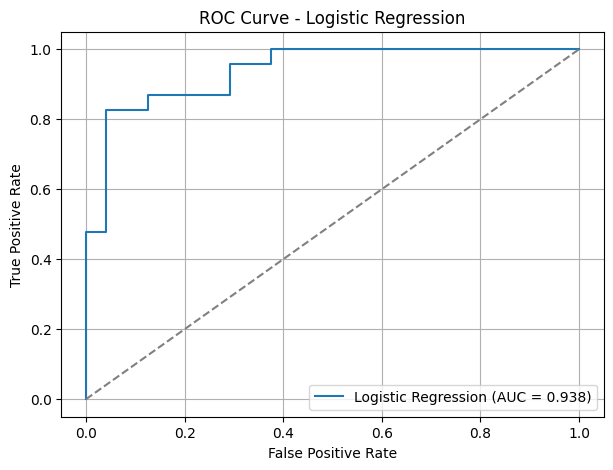

AUC Logistic Regression: 0.9384057971014492


In [30]:
# ROC-AUC Curve - Logistic Regression
idx_tinggi = list(best_lr.classes_).index("Tinggi")
y_prob_lr = best_lr.predict_proba(X_test_lr)[:, idx_tinggi]
y_test_bin = (y_test_lr == "Tinggi").astype(int)

fpr_lr, tpr_lr, _ = roc_curve(y_test_bin, y_prob_lr)
auc_lr = roc_auc_score(y_test_bin, y_prob_lr)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()
print("AUC Logistic Regression:", auc_lr)

### **Penjelasan Langkah 7: Menghitung Odds Ratio (Rasio Kemungkinan)**

Ini adalah bagian yang sangat penting dalam analisis biologi dan epidemiologi kesehatan:

* **Koefisien (`coef_`)**:
  * Merupakan nilai arah hubungan. Jika positif, variabel tersebut meningkatkan peluang target bernilai 'Tinggi'. Jika negatif, variabel tersebut menurunkan peluangnya.
* **`np.exp(koefisien)` atau Odds Ratio**:
  * Karena rumus dasar regresi logistik menggunakan logaritma, kita harus menaikkan nilai koefisien ke bentuk eksponensial (`np.exp`) untuk mendapatkan nilai **Odds Ratio**.
  * **Interpretasi Odds Ratio (OR)**:
    * Jika nilai **OR > 1**: Berarti variabel tersebut meningkatkan kemungkinan terjadinya CFR yang 'Tinggi' (misalnya wilayah Americas memiliki OR > 2, berarti negara di Americas memiliki peluang 2 kali lebih besar untuk mengalami kematian CFR tinggi dibandingkan wilayah referensi).
    * Jika nilai **OR < 1**: Berarti variabel tersebut bersifat protektif atau menurunkan peluang terjadinya CFR yang tinggi.

In [31]:
# Odds Ratio dari Koefisien
nama_fitur_lr = best_lr.named_steps['preprocessing'].get_feature_names_out()
koefisien = best_lr.named_steps['classifier'].coef_[0]
odds_ratio = np.exp(koefisien)

tabel_koefisien = pd.DataFrame({
    'Fitur': nama_fitur_lr,
    'Koefisien': koefisien,
    'Odds Ratio': odds_ratio
}).sort_values(by='Koefisien', ascending=False)

print(tabel_koefisien)

                                  Fitur  Koefisien  Odds Ratio
3                  cat__Region_Americas   0.760419    2.139172
5                    cat__Region_Europe   0.670260    1.954745
4     cat__Region_Eastern Mediterranean   0.298230    1.347472
2                    cat__Region_Africa   0.126297    1.134619
1  num__New Cases per 100k pop (7 days)  -0.314756    0.729967
6           cat__Region_South-East Asia  -0.508119    0.601626
7           cat__Region_Western Pacific  -1.692077    0.184137
0         num__Total Cases per 100k pop  -1.815263    0.162795


---
## **Husain Haekal: PCA & K-Means**

### **Penjelasan Langkah 1: Mempersiapkan Data dan Standardisasi Skala**

Di sel kode berikut, kita mempersiapkan data untuk analisis kelompok tanpa pengawasan (*unsupervised learning*):

* **Analisis Tanpa Pengawasan (Unsupervised Learning)**:
  * Berbeda dengan model sebelumnya yang menebak label 'Tinggi'/'Rendah' yang sudah kita buat, analisis ini membiarkan komputer mencari sendiri pola pengelompokan alami dari data tanpa kita beri tahu jawabannya.
* **`df_clean_pca.fillna(0)`**:
  * Mengisi semua nilai yang kosong/hilang (NaN) di dalam tabel dengan angka `0` agar perhitungan matematika saat pengelompokan tidak error.
* **`StandardScaler().fit_transform(X_cluster)`**:
  * Melakukan standardisasi skala data. Karena jumlah kasus bisa bernilai jutaan sedangkan kasus baru bernilai ratusan, kita menyamakan rentang nilainya terlebih dahulu.
  * **`fit_transform`** adalah perintah gabungan untuk menghitung nilai rata-rata dan standar deviasi sekaligus langsung mengubah data asli ke skala baru yang setara.

In [32]:
# Membuat salinan data khusus untuk Analisis Unsupervised (PCA & K-Means)
df_pca = df_master.copy()

# Filter dan isi nilai kosong
df_clean_pca = df_pca[df_pca['Total Cases'] > 0].copy()
df_clean_pca = df_clean_pca.fillna(0)

# Memilih fitur-fitur penting
fitur_unsupervised = ['Total Cases per 100k pop', 'Total Deaths per 100k pop', 'New Cases per 100k pop (7 days)']
X_cluster = df_clean_pca[fitur_unsupervised]

# Standardisasi skala data
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X_cluster)
print("Proses standarisasi skala selesai!")

Proses standarisasi skala selesai!


### **Penjelasan Langkah 2: Menentukan Jumlah Kelompok Terbaik (Elbow Method)**

Sebelum mengelompokkan data, kita harus menentukan berapa jumlah kelompok (*cluster*) terbaik menggunakan metode siku (Elbow Method):

* **`KMeans(n_clusters=k_val, random_state=42)`**:
  * Ini adalah algoritma **K-Means Clustering**. Algoritma ini mengelompokkan data berdasarkan kedekatan jarak antar data.
  * **`n_clusters=k_val`**: Mencoba mengelompokkan data dari 1 kelompok hingga 10 kelompok secara bergantian.
* **`km.inertia_`**:
  * Inertia adalah total jarak kuadrat antara setiap titik data dengan pusat kelompoknya (centroid). Semakin kecil nilai inertia, kelompoknya semakin rapat.
* **Grafik Elbow Method**:
  * Kita mencari titik di mana penurunan nilai inertia mulai melandai (membentuk lekukan seperti siku tangan). Titik siku tersebut menunjukkan jumlah kelompok (K) yang paling optimal untuk digunakan.

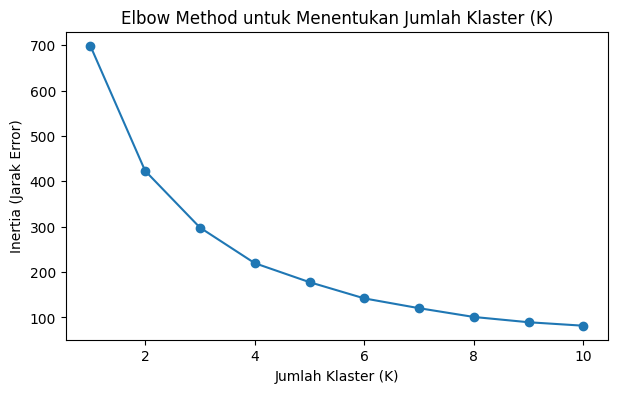

In [33]:
# Elbow Method untuk menentukan jumlah klaster (K) terbaik
inertia_list = []
for k_val in range(1, 11):
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    km.fit(X_scaled_pca)
    inertia_list.append(km.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia_list, marker='o')
plt.title("Elbow Method untuk Menentukan Jumlah Klaster (K)")
plt.xlabel("Jumlah Klaster (K)")
plt.ylabel("Inertia (Jarak Error)")
plt.show()

### **Penjelasan Langkah 3: Menjalankan K-Means dan Mereduksi Dimensi dengan PCA**

Setelah menentukan jumlah kelompok terbaik (K=3), kita menjalankan pengelompokan dan menyederhanakan data agar bisa digambar dalam grafik 2 dimensi:

* **`kmeans_pca.fit_predict(X_scaled_pca)`**:
  * Memerintahkan komputer untuk mengelompokkan negara-negara ke dalam 3 kelompok (Klaster 0, 1, dan 2) sekaligus melabeli setiap negara dengan hasil kelompoknya.
* **`PCA(n_components=2)`**:
  * **PCA (*Principal Component Analysis*)** adalah teknik untuk menyederhanakan (reduksi dimensi) variabel data yang banyak menjadi lebih sedikit tanpa kehilangan banyak informasi penting.
  * Karena kita menggunakan 3 indikator (Total Kasus, Total Kematian, Kasus Baru), kita tidak bisa menggambarnya langsung di kertas biasa (2D). Alat ini menyederhanakan 3 indikator tersebut menjadi 2 sumbu koordinat baru saja, yaitu **PCA 1** dan **PCA 2**.
* **`pca_model.explained_variance_ratio_`**:
  * Menghitung seberapa banyak persentase informasi dari data asli yang berhasil dipertahankan setelah kita sederhanakan sumbunya.

In [34]:
# Jalankan K-Means dengan K=3
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean_pca['Cluster'] = kmeans_pca.fit_predict(X_scaled_pca)

# PCA untuk reduksi dimensi 2D
pca_model = PCA(n_components=2)
hasil_pca_data = pca_model.fit_transform(X_scaled_pca)
df_clean_pca['PCA_1'] = hasil_pca_data[:, 0]
df_clean_pca['PCA_2'] = hasil_pca_data[:, 1]

print(f"Variansi yang dijelaskan oleh PCA: {pca_model.explained_variance_ratio_.sum()*100:.2f}%")

Variansi yang dijelaskan oleh PCA: 82.70%


### **Penjelasan Langkah 4: Membuat Grafik Sebaran Kelompok (Scatter Plot)**

Di sel kode ini, kita menggambar peta sebaran negara berdasarkan kelompoknya masing-masing:

* **`sns.scatterplot(...)`**:
  * Membuat grafik titik (scatter plot). Sumbu X adalah PCA 1 dan sumbu Y adalah PCA 2.
  * **`hue='Cluster'`**: Mewarnai titik-titik negara berdasarkan hasil kelompok K-Means yang telah didapatkan (setiap warna mewakili klaster yang berbeda).
  * **`palette='viridis'`**: Memilih kombinasi tema warna grafik.

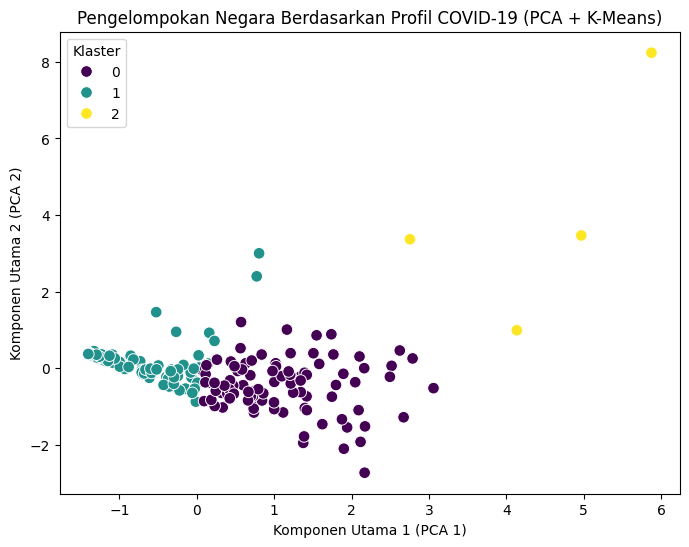

In [35]:
# Visualisasi Sebaran Klaster dengan PCA
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean_pca, x='PCA_1', y='PCA_2', hue='Cluster', palette='viridis', s=70)
plt.title("Pengelompokan Negara Berdasarkan Profil COVID-19 (PCA + K-Means)")
plt.xlabel("Komponen Utama 1 (PCA 1)")
plt.ylabel("Komponen Utama 2 (PCA 2)")
plt.legend(title="Klaster")
plt.show()

### **Penjelasan Langkah 5: Membaca Karakteristik Kelompok dan Perbandingannya**

Langkah terakhir adalah menerjemahkan arti biologis atau profil dari masing-masing kelompok yang terbentuk:

* **`df_clean_pca.groupby('Cluster')[fitur_unsupervised].mean()`**:
  * Menghitung nilai rata-rata dari indikator COVID-19 untuk masing-masing kelompok. Dari sini kita bisa menganalisis profil kelompok, misalnya:
    * Kelompok mana yang memiliki tingkat kematian sangat tinggi.
    * Kelompok mana yang penularan kasus barunya sangat cepat.
* **`pd.crosstab(df_clean_pca['Cluster'], df_clean_pca['Region'])`**:
  * Membuat tabel silang untuk melihat distribusi penyebaran geografis wilayah benua (*Region*) di dalam masing-masing kelompok bentukan komputer.

In [36]:
# Interpretasi hasil klaster
print("\nRata-rata nilai per Klaster:")
print(df_clean_pca.groupby('Cluster')[fitur_unsupervised].mean())

print("\nPerbandingan Klaster dengan Wilayah (Region):")
print(pd.crosstab(df_clean_pca['Cluster'], df_clean_pca['Region']))


Rata-rata nilai per Klaster:
         Total Cases per 100k pop  Total Deaths per 100k pop  \
Cluster                                                        
0                    35037.027194                 219.098452   
1                     6450.928640                  49.106015   
2                    46798.082000                 220.220500   

         New Cases per 100k pop (7 days)  
Cluster                                   
0                              94.316699  
1                              20.553868  
2                            1098.652250  

Perbandingan Klaster dengan Wilayah (Region):
Region   Africa  Americas  Eastern Mediterranean  Europe  Other  \
Cluster                                                           
0             2        33                      2      47      0   
1            47        21                     20      13      1   
2             0         2                      0       1      0   

Region   South-East Asia  Western Pacific  
Cluster

### **Daftar Lengkap Negara Berdasarkan Klaster K-Means**

Di bawah ini adalah rincian lengkap mengenai jumlah negara serta daftar negara dan wilayahnya yang dikelompokkan ke dalam Klaster 0, 1, dan 2.

In [38]:
# Menampilkan opsi Pandas agar tidak ada baris yang terpotong
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 1. Menampilkan jumlah negara pada masing-masing klaster
print("=========================================================")
print("JUMLAH NEGARA PADA MASING-MASING KLASTER")
print("=========================================================")
print(df_clean_pca['Cluster'].value_counts().sort_index())
print("\n")

# 2. Menampilkan daftar lengkap seluruh nama negara berdasarkan klaster
for cluster_id in sorted(df_clean_pca['Cluster'].unique()):
    print("=========================================================")
    print(f"DAFTAR NEGARA DI KLASTER {cluster_id}")
    print("=========================================================")

    # Memfilter data klaster dan mengurutkannya secara alfabetis berdasarkan nama negara
    df_cluster = df_clean_pca[df_clean_pca['Cluster'] == cluster_id][['Country', 'Region', 'Total Cases per 100k pop']].sort_values(by='Country')

    # Menampilkan hasil
    display(df_cluster)
    print("\n")

JUMLAH NEGARA PADA MASING-MASING KLASTER
Cluster
0     93
1    136
2      4
Name: count, dtype: int64


DAFTAR NEGARA DI KLASTER 0


,Country,Region,Total Cases per 100k pop
153,Andorra,Europe,59725.620
14,Argentina,Americas,21457.234
92,Armenia,Europe,14825.086
156,Aruba,Americas,40246.895
13,Australia,Western Pacific,39655.980
24,Austria,Europe,56205.078
78,Bahrain,Eastern Mediterranean,39663.782
129,Barbados,Americas,35486.385
30,Belgium,Europe,39089.863
140,Belize,Americas,17255.324




DAFTAR NEGARA DI KLASTER 1


,Country,Region,Total Cases per 100k pop
116,Afghanistan,Eastern Mediterranean,505.192
99,Albania,Europe,11472.270
104,Algeria,Africa,617.021
208,American Samoa,Western Pacific,14886.679
128,Angola,Africa,313.790
220,Anguilla,Americas,25703.240
205,Antigua and Barbuda,Americas,9198.501
74,Azerbaijan,Europe,8073.971
162,Bahamas,Americas,9452.401
43,Bangladesh,South-East Asia,1224.477




DAFTAR NEGARA DI KLASTER 2


,Country,Region,Total Cases per 100k pop
111,Martinique,Americas,58499.727
224,Montserrat,Americas,26525.305
5,Republic of Korea,Western Pacific,47327.591
59,Slovenia,Europe,54839.705
